In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_uci.csv")

In [9]:
df.shape

(920, 16)

In [11]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [14]:
df.dtypes

id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object

In [19]:
(df["trestbps"] == 0).sum()

np.int64(1)

In [21]:
(df["chol"] == 0).sum()

np.int64(172)

In [22]:
(df["ca"] == 0).sum()

np.int64(181)

In [25]:
df["num"].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [27]:
df["num"] = (df["num"] > 0).astype(int)

In [29]:
df.loc[df["chol"] == 0 , "dataset"].value_counts()

dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

In [82]:
df.loc[df["fbs"] == 0 , "dataset"].value_counts()

dataset
Hungary          265
Cleveland        259
VA Long Beach    125
Switzerland       43
Name: count, dtype: int64

In [31]:
df["dataset"].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [33]:
df[df["chol"] == 0][
    ["dataset", "age", "sex", "trestbps", "chol", "num"]
].head(10)

,dataset,age,sex,trestbps,chol,num
597,Switzerland,32,Male,95.0,0.0,1
598,Switzerland,34,Male,115.0,0.0,1
599,Switzerland,35,Male,NaN,0.0,1
600,Switzerland,36,Male,110.0,0.0,1
601,Switzerland,38,Female,105.0,0.0,1
602,Switzerland,38,Female,110.0,0.0,1
603,Switzerland,38,Male,100.0,0.0,0
604,Switzerland,38,Male,115.0,0.0,1
605,Switzerland,38,Male,135.0,0.0,1
606,Switzerland,38,Male,150.0,0.0,1


In [34]:
df.loc[df["trestbps"] == 0, "trestbps"] = np.nan

In [37]:
df.loc[df["chol"] == 0, "chol"] = np.nan

In [40]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     60
chol        202
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [47]:
X = df.drop(columns = ["id","dataset","num"])
y = df["num"]
print(X.shape)
y.shape

(920, 13)


(920,)

In [51]:
from sklearn.model_selection import train_test_split,

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print(X_train.shape)
print(X_test.shape)

(736, 13)
(184, 13)


In [87]:
numerical_features = ["age","trestbps","chol", "thalch", "oldpeak", "ca"]
categorical_features = ["sex", "cp","fbs",
    "restecg",
    "exang",
    "slope",
    "thal"]
for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

In [88]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [89]:
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "median" , add_indicator = True)),("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer",SimpleImputer(strategy = "constant" , fill_value = "Unknown")),
    ("encoder",OneHotEncoder(handle_unknown = "ignore"))
    
])
#Why Unknown?  your thal column has 486 missing values. Instead of assuming those patients had normal thallium results, we explicitly preserve the fact that their results are unavailable.

In [90]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [98]:
import numpy as np

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

    X_test[col] = X_test[col].map(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

In [105]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Training shape: (736, 34)
Testing shape: (184, 34)


In [108]:
import numpy as np

print("Missing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())

Missing values in training: 0
Missing values in testing: 0


In [110]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 1000)
model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [114]:
y_pred = model.predict(X_test_processed)

In [121]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
accuracy = accuracy_score(y_test, y_pred)
accuracy


0.8532608695652174

In [119]:
print(confusion_matrix(y_test, y_pred))

[[66 16]
 [11 91]]


In [122]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83        82
           1       0.85      0.89      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



In [124]:
y_prob = model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9142754662840746


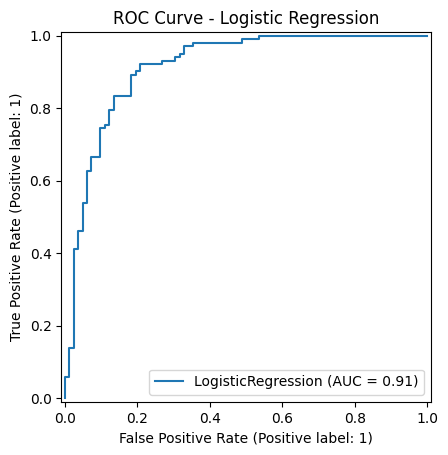

In [126]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(
    model,
    X_test_processed,
    y_test
)

plt.title("ROC Curve - Logistic Regression")
plt.show()

In [130]:
# 5 - Fold Cross Validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

model_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", LogisticRegression(max_iter = 1000))
])

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

cv_scores = cross_val_score(model_pipeline,
                            X_train,
                            y_train,
                            cv=cv,
                            scoring = "roc_auc")

print("Fold ROC-AUC scores:", cv_scores)
print("Mean ROC-AUC:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Fold ROC-AUC scores: [0.86437546 0.88855535 0.90291807 0.89786756 0.92573887]
Mean ROC-AUC: 0.8958910626661304
Standard Deviation: 0.01995606580361258


In [134]:
# Threshold Experimentation part

from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)


threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

threshold_model.fit(X_fit, y_fit)

y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

In [139]:
from sklearn.metrics import recall_score, precision_score, confusion_matrix

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred
    ).ravel()

    sensitivity = recall_score(y_val, y_pred)

    specificity = tn / (tn + fp)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    print(f"\nThreshold: {threshold}")
    print(f"Sensitivity: {sensitivity:.3f}")
    print(f"Specificity: {specificity:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")


Threshold: 0.3
Sensitivity: 0.927
Specificity: 0.606
Precision: 0.745
False Positives: 26
False Negatives: 6

Threshold: 0.4
Sensitivity: 0.902
Specificity: 0.682
Precision: 0.779
False Positives: 21
False Negatives: 8

Threshold: 0.5
Sensitivity: 0.817
Specificity: 0.727
Precision: 0.788
False Positives: 18
False Negatives: 15

Threshold: 0.6
Sensitivity: 0.817
Specificity: 0.803
Precision: 0.838
False Positives: 13
False Negatives: 15

Threshold: 0.7
Sensitivity: 0.768
Specificity: 0.864
Precision: 0.875
False Positives: 9
False Negatives: 19


In [141]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [142]:
test_prob = final_model.predict_proba(X_test)[:, 1]

best_threshold = 0.4

y_test_pred = (test_prob >= best_threshold).astype(int)

print(classification_report(y_test, y_test_pred))
print(confusion_matrix(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.88      0.74      0.81        82
           1       0.82      0.92      0.87       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.84       184
weighted avg       0.85      0.84      0.84       184

[[61 21]
 [ 8 94]]


In [143]:
#Finalllllll Steps

In [146]:
lr_final = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_final.fit(X_train, y_train)


y_prob = lr_final.predict_proba(X_test)[:, 1]

y_pred = (y_prob >= 0.4).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[61 21]
 [ 8 94]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.74      0.81        82
           1       0.82      0.92      0.87       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.84       184
weighted avg       0.85      0.84      0.84       184



In [149]:

# import joblib

# lr_artifact = {
#     "model": lr_final,
#     "threshold": 0.4,
#     "model_name": "Logistic Regression"
# }

# joblib.dump(lr_artifact, "logistic_regression_model.pkl")

# to load the model
#lr_artifact = joblib.load("logistic_regression_model.pkl")
#lr_final = lr_artifact["model"]
#threshold = lr_artifact["threshold"]

In [153]:
# df.to_csv("heart_disease_cleaned.csv", index=False)

In [154]:
# import json
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score,
#     confusion_matrix,
#     classification_report
# )

# # Predictions
# y_pred = final_model.predict(X_test)

# # Probability of class 1
# y_prob = final_model.predict_proba(X_test)[:, 1]

# # Calculate metrics
# metrics = {
#     "accuracy": accuracy_score(y_test, y_pred),
#     "precision": precision_score(y_test, y_pred, zero_division=0),
#     "recall": recall_score(y_test, y_pred, zero_division=0),
#     "f1_score": f1_score(y_test, y_pred, zero_division=0),
#     "roc_auc": roc_auc_score(y_test, y_prob),
#     "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
#     "classification_report": classification_report(
#         y_test,
#         y_pred,
#         output_dict=True,
#         zero_division=0
#     )
# }

# # Save to JSON
# with open("metrics.json", "w") as file:
#     json.dump(metrics, file, indent=4)

# print("Metrics saved successfully to metrics.json")

Metrics saved successfully to metrics.json
